In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../DATA/online_shoppers_intention.csv')

In [3]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [5]:
df['Revenue'].value_counts()

Revenue
False    10422
True      1908
Name: count, dtype: int64

In [6]:
df['Weekend'] = df['Weekend'].map({True: 1, False: 0})

In [7]:
df['Revenue'] = df['Revenue'].map({True: 1, False: 0})

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [9]:
df['Revenue'].value_counts()

Revenue
0    10422
1     1908
Name: count, dtype: int64

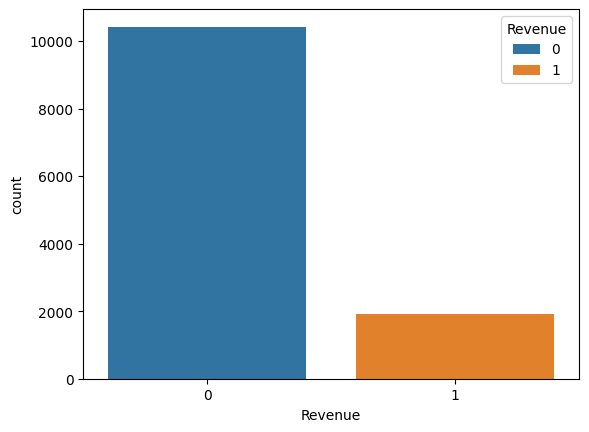

In [11]:
sns.countplot(data=df, x='Revenue', hue='Revenue');

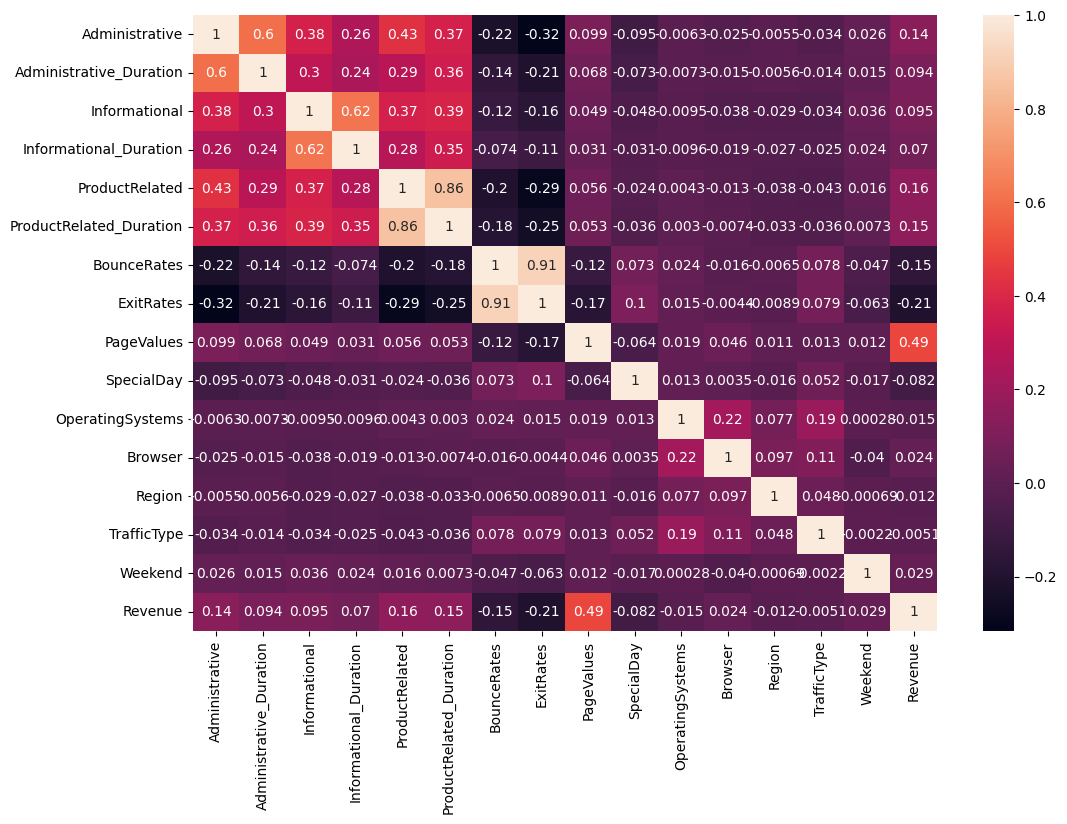

In [12]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True);

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.ensemble import IsolationForest

In [14]:
X = df.drop('Revenue', axis=1)

In [15]:
y = df['Revenue']

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=104)

In [17]:
num_features = X_train.select_dtypes(exclude='object').columns.tolist()
cat_features = X_train.select_dtypes(include='object').columns.tolist()

In [18]:
iso_forest = IsolationForest(contamination=0.01, n_jobs=-1, random_state=104, n_estimators=100)

In [19]:
mask = iso_forest.fit_predict(X_train[num_features])

In [20]:
X_train_cleaned = X_train[mask==1]
y_train_cleaned = y_train[mask==1]

In [21]:
X_train.shape

(9864, 17)

In [22]:
X_train_cleaned.shape

(9765, 17)

In [24]:
num_transformer = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler_2', StandardScaler())
])

In [25]:
cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [26]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', cat_transformer, cat_features),
        ('num', num_transformer, num_features)
    ],
    remainder='passthrough'
)

In [27]:
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegressionCV(Cs=10, cv=7, penalty='l2', solver='lbfgs',
                                   max_iter=500, n_jobs=-1, class_weight='balanced', random_state=104))
])

In [28]:
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore')

In [29]:
%%time
pipe.fit(X_train_cleaned, y_train_cleaned)

CPU times: total: 297 ms
Wall time: 14.6 s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transfor

In [30]:
y_pred = pipe.predict(X_test)
y_pred_proba = pipe.predict_proba(X_test)[:, 1]
y_train_proba = pipe.predict_proba(X_train)[:, 1]

In [37]:
best_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_model.C_}")

Лучшее значение C: [0.04641589]


In [31]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
roc_auc_test = roc_auc_score(y_test, y_pred_proba)
roc_auc_train = roc_auc_score(y_train, y_train_proba)

In [32]:
accuracy

0.8414436334144363

In [33]:
precision

0.5070422535211268

In [34]:
recall

0.7218045112781954

In [35]:
roc_auc_train

0.916874020191637

In [36]:
roc_auc_test

0.896452548885518

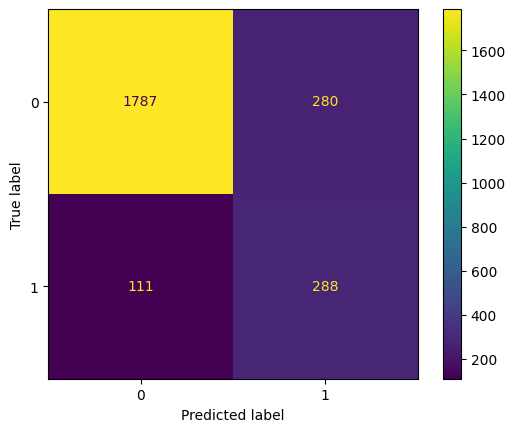

In [39]:
ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test);

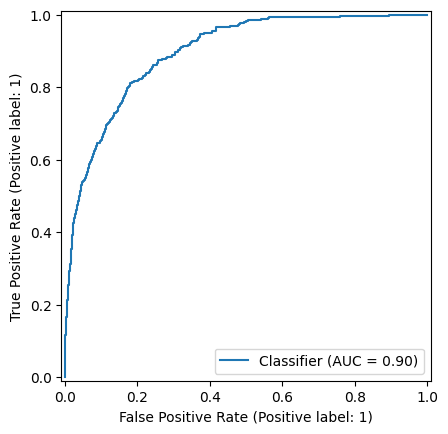

In [40]:
RocCurveDisplay.from_predictions(y_test, y_pred_proba);

In [41]:
%%time
pipe.fit(X, y)

CPU times: total: 188 ms
Wall time: 4.67 s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transfor

In [42]:
y_full_pred = pipe.predict_proba(X)[:, 1]

In [43]:
best_final_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_final_model.C_}")

Лучшее значение C: [0.0001]


In [44]:
roc_auc_full = roc_auc_score(y, y_full_pred)

In [45]:
roc_auc_full

0.879439387411004

In [46]:
custom_shopping_df = pd.DataFrame([
    {
        'Administrative': 0, 'Administrative_Duration': 0.0,
        'Informational': 0, 'Informational_Duration': 0.0,
        'ProductRelated': 1, 'ProductRelated_Duration': 12.5,
        'BounceRates': 0.20, 'ExitRates': 0.20,
        'PageValues': 0.0, 'SpecialDay': 0.0,
        'Month': 'May', 'OperatingSystems': 2, 'Browser': 2,
        'Region': 1, 'TrafficType': 1, 
        'VisitorType': 'Returning_Visitor', 'Weekend': False
    },
    {
        'Administrative': 3, 'Administrative_Duration': 84.0,
        'Informational': 2, 'Informational_Duration': 120.0,
        'ProductRelated': 28, 'ProductRelated_Duration': 1140.5,
        'BounceRates': 0.00, 'ExitRates': 0.01,
        'PageValues': 42.8,
        'SpecialDay': 0.8,
        'Month': 'Nov', 'OperatingSystems': 2, 'Browser': 2,
        'Region': 3, 'TrafficType': 2, 
        'VisitorType': 'New_Visitor', 'Weekend': True
    }
])

In [47]:
custom_shopping_df = custom_shopping_df[X_train.columns]

In [48]:
custom_shopping_df

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
0,0,0.0,0,0.0,1,12.5,0.2,0.20,0.0,0.0,May,2,2,1,1,Returning_Visitor,False
1,3,84.0,2,120.0,28,1140.5,0.0,0.01,42.8,0.8,Nov,2,2,3,2,New_Visitor,True


In [49]:
preds = pipe.predict(custom_shopping_df)
preds_proba = pipe.predict_proba(custom_shopping_df)

In [50]:
classes_map = {
    0: "ОТКАЗ (Пользователь покинет сайт без покупки) 🔴",
    1: "КОНВЕРСИЯ (Высокая вероятность совершения покупки!) 🟢"
}

expected_list = [
    "СЛУЧАЙНЫЙ КЛИЕНТ: КОРОТКИЙ ПРОСМОТР ОДНОЙ СТРАНИЦЫ В БУДНИ",
    "ЦЕЛЕВОЙ ПОКУПАТЕЛЬ: АКТИВНЫЙ ИНТЕРЕС И ВЫСОКАЯ ЦЕННОСТЬ СЕССИИ"
]

print("=" * 90)
print("🛒  ДЕПЛОЙ СИСТЕМЫ ПРЕДСКАЗАНИЯ ПОКУПАТЕЛЬСКОЙ СПОСОБНОСТИ В E-COMMERCE")
print("=" * 90)

for idx in range(2):
    class_out = preds[idx]
    prob = preds_proba[idx][class_out] * 100
    
    print(f"\n💻 МОНИТОРИНГ СЕССИИ ПОЛЬЗОВАТЕЛЯ №{idx + 1}:")
    print(f" -> Поведение на сайте: {expected_list[idx]}")
    print(f" -> Вердикт ИИ-модели:   {classes_map[class_out]}")
    print(f" -> Уверенность логита:  {prob:.2f}% 📊")
    print("-" * 90)

🛒  ДЕПЛОЙ СИСТЕМЫ ПРЕДСКАЗАНИЯ ПОКУПАТЕЛЬСКОЙ СПОСОБНОСТИ В E-COMMERCE

💻 МОНИТОРИНГ СЕССИИ ПОЛЬЗОВАТЕЛЯ №1:
 -> Поведение на сайте: СЛУЧАЙНЫЙ КЛИЕНТ: КОРОТКИЙ ПРОСМОТР ОДНОЙ СТРАНИЦЫ В БУДНИ
 -> Вердикт ИИ-модели:   ОТКАЗ (Пользователь покинет сайт без покупки) 🔴
 -> Уверенность логита:  80.34% 📊
------------------------------------------------------------------------------------------

💻 МОНИТОРИНГ СЕССИИ ПОЛЬЗОВАТЕЛЯ №2:
 -> Поведение на сайте: ЦЕЛЕВОЙ ПОКУПАТЕЛЬ: АКТИВНЫЙ ИНТЕРЕС И ВЫСОКАЯ ЦЕННОСТЬ СЕССИИ
 -> Вердикт ИИ-модели:   КОНВЕРСИЯ (Высокая вероятность совершения покупки!) 🟢
 -> Уверенность логита:  56.33% 📊
------------------------------------------------------------------------------------------


In [51]:
class_percents = df['Revenue'].value_counts(normalize=True) * 100

baseline_string = f"0: {class_percents[0]:.1f}%, 1: {class_percents[1]:.1f}%"
print(f"{baseline_string}")

0: 84.5%, 1: 15.5%


In [52]:
import json
import os

advanced_report = {
    "project": "Online Shoppers Intention Prediction",
    "model": "LogisticRegressionCV",
    "trained_date": '2026-08',
    "test_parameters": {
        "cv": best_model.cv,
        "penalty": best_model.penalty,
        "solver":best_model.solver,
        "C": best_model.C_.tolist()[0],
    },
    "final_parameters": {
        "cv": best_final_model.cv,
        "penalty": best_final_model.penalty,
        "solver":best_final_model.solver,
        "C": best_final_model.C_.tolist()[0],
    },
    "metrics": {
        "Accuracy Score": accuracy,
        "Precision Score": precision,
        "Recall": recall,
        "ROC AUC Score Train": roc_auc_train,
        "ROC AUC Score Test": roc_auc_test,
        "ROC AUC Score Full": roc_auc_full,
        "Class Balance": baseline_string
    }
}


filename = "model_description.json"

with open(filename, "w", encoding="utf-8") as f:
    json.dump(advanced_report, f, indent=4, ensure_ascii=False)

In [53]:
from joblib import dump, load

In [55]:
os.makedirs('model', exist_ok=True)

In [56]:
dump(pipe, "model/online_shoppers_intention_predict_logistic_regression_cv_2026_v1.pkl")

['model/online_shoppers_intention_predict_logistic_regression_cv_2026_v1.pkl']

In [57]:
loaded_pipe = load("model/online_shoppers_intention_predict_logistic_regression_cv_2026_v1.pkl")

In [59]:
preds = loaded_pipe.predict(custom_shopping_df)
preds_proba = loaded_pipe.predict_proba(custom_shopping_df)

In [60]:
classes_map = {
    0: "ОТКАЗ (Пользователь покинет сайт без покупки) 🔴",
    1: "КОНВЕРСИЯ (Высокая вероятность совершения покупки!) 🟢"
}

expected_list = [
    "СЛУЧАЙНЫЙ КЛИЕНТ: КОРОТКИЙ ПРОСМОТР ОДНОЙ СТРАНИЦЫ В БУДНИ",
    "ЦЕЛЕВОЙ ПОКУПАТЕЛЬ: АКТИВНЫЙ ИНТЕРЕС И ВЫСОКАЯ ЦЕННОСТЬ СЕССИИ"
]

print("=" * 90)
print("🛒  ДЕПЛОЙ СИСТЕМЫ ПРЕДСКАЗАНИЯ ПОКУПАТЕЛЬСКОЙ СПОСОБНОСТИ В E-COMMERCE")
print("=" * 90)

for idx in range(2):
    class_out = preds[idx]
    prob = preds_proba[idx][class_out] * 100
    
    print(f"\n💻 МОНИТОРИНГ СЕССИИ ПОЛЬЗОВАТЕЛЯ №{idx + 1}:")
    print(f" -> Поведение на сайте: {expected_list[idx]}")
    print(f" -> Вердикт ИИ-модели:   {classes_map[class_out]}")
    print(f" -> Уверенность логита:  {prob:.2f}% 📊")
    print("-" * 90)

🛒  ДЕПЛОЙ СИСТЕМЫ ПРЕДСКАЗАНИЯ ПОКУПАТЕЛЬСКОЙ СПОСОБНОСТИ В E-COMMERCE

💻 МОНИТОРИНГ СЕССИИ ПОЛЬЗОВАТЕЛЯ №1:
 -> Поведение на сайте: СЛУЧАЙНЫЙ КЛИЕНТ: КОРОТКИЙ ПРОСМОТР ОДНОЙ СТРАНИЦЫ В БУДНИ
 -> Вердикт ИИ-модели:   ОТКАЗ (Пользователь покинет сайт без покупки) 🔴
 -> Уверенность логита:  80.34% 📊
------------------------------------------------------------------------------------------

💻 МОНИТОРИНГ СЕССИИ ПОЛЬЗОВАТЕЛЯ №2:
 -> Поведение на сайте: ЦЕЛЕВОЙ ПОКУПАТЕЛЬ: АКТИВНЫЙ ИНТЕРЕС И ВЫСОКАЯ ЦЕННОСТЬ СЕССИИ
 -> Вердикт ИИ-модели:   КОНВЕРСИЯ (Высокая вероятность совершения покупки!) 🟢
 -> Уверенность логита:  56.33% 📊
------------------------------------------------------------------------------------------
